<a href="https://colab.research.google.com/github/Mufliha-Hafsyah/Machine-Learning/blob/main/Week11/Praktikum5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS11 - Klasifikasi 2**<hr>
# **Praktikum 5: Klasifikasi Citra Siang dan Malam**<hr>

## **Langkah 0 - Import Library**

In [1]:
	# Import Required Libraries
	from pathlib import Path
	import matplotlib.image as mpimg
	import matplotlib.pyplot as plt
	import cv2
	import random
	import numpy as np
	import pandas as pd

**Lakukan ekstraksi data gambar, kemudian definisikan lokasi gambar. Pada contoh ini, folder gambar berlokasi sama dengan lokasi file python.**

In [ ]:
!unzip -q images.zip
!ls

In [3]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

## **Langkah 1 - Load Data dan Visualisasikan**

In [28]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

**Load gambar training**

In [29]:
	# Load training data
	train_img = load_dataset(train_dir)

**Lakukan pengecekan pada salah satu data pada list. List harus berisi tuple dengan dua data, yaitu data gambar dan label dari gambar.**

In [30]:
	# Check the first data
	# It should be a tuple consist of arrays of image and image labels
	train_img[0]

(array([[[10, 15, 18],
         [ 1,  6,  9],
         [26, 30, 31],
         ...,
         [ 6,  7,  2],
         [14, 15, 10],
         [ 9, 10,  5]],
 
        [[13, 17, 20],
         [ 4,  8, 11],
         [23, 27, 28],
         ...,
         [10, 11,  6],
         [13, 14,  9],
         [ 3,  4,  0]],
 
        [[17, 18, 22],
         [ 8,  9, 13],
         [22, 23, 25],
         ...,
         [ 9, 10,  5],
         [12, 13,  8],
         [ 0,  1,  0]],
 
        ...,
 
        [[11, 10,  6],
         [ 1,  0,  0],
         [27, 26, 22],
         ...,
         [ 0,  4,  0],
         [ 7, 14,  7],
         [11, 21, 13]],
 
        [[31, 30, 26],
         [ 1,  0,  0],
         [ 6,  5,  1],
         ...,
         [ 8, 15,  8],
         [33, 40, 33],
         [39, 49, 41]],
 
        [[14, 13,  9],
         [ 6,  5,  1],
         [26, 25, 21],
         ...,
         [ 0,  7,  0],
         [19, 26, 19],
         [ 5, 12,  5]]], dtype=uint8),
 'night')

**Cek ukuran gambar secara acak**

In [7]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_img))

	# Check img size
	print(f'Image {pick_random}')
	print(train_img[pick_random][0].shape)

Image 222
(471, 640, 3)


**Tampilkan gambar untuk inspeksi secara visual. Buatlah fungsi untuk membantu memvisualkan gambar**

In [8]:
	# Function to Visualize
	def random_img_viz(img_list):
	    rand_num = np.random.randint(0, len(img_list))

	    img = img_list[rand_num][0]
	    label = img_list[rand_num][1]
	    label_str = 'day' if label == 1 else 'night'

	    plt.imshow(img)
	    print(f'Shape\t: {img.shape}')
	    print(f'Label\t: {label}')

**Lakukan visualisasi gambar secara acak**

Shape	: (439, 640, 3)
Label	: night


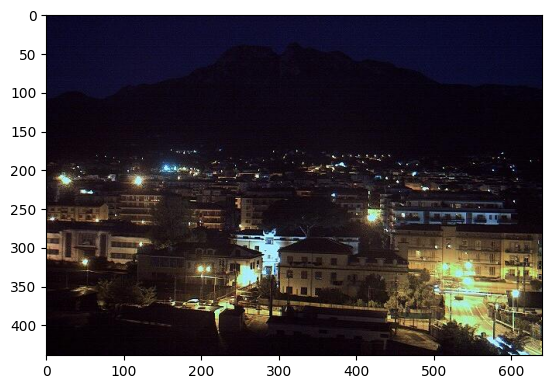

In [9]:
random_img_viz(train_img)

## **Langkah 3 - Pra Pengolahan Data**
**Fungsi berikut untuk menstandarkan ukuran gambar.**

In [10]:
	def standarized_input(image):
	    # resize to w: 1100, h:600
	    std_img = cv2.resize(image, (1100,600))

	    return std_img

**Selanjutnya, buatlah fungsi untuk kebutuhan encoding label.**

In [11]:
	def label_encoder(label):
	    # Encode the label
	    # day as 1; night as 0
	    num_val = 0

	    if(label == 'day'):
	        num_val = 1

	    return num_val

**Terakhir, buatlah fungsi untuk melakukan kedua hal tersebut secara sekaligus untuk semua gambar dalam list.**

In [12]:
	def preprocess(img_list):
	    std_img_list = []

	    for item in img_list:
	        image = item[0]
	        label = item[1]

	        # Standarized the image
	        std_img = standarized_input(image)

	        # Create the label
	        img_label = label_encoder(label)

	        std_img_list.append((std_img, img_label))

	    return std_img_list

**Lakukan pra pengolahan data pada data training.**

In [13]:
train_std_img_list = preprocess(train_img)

**Lakukan pengecekan ukuran gambar secara acak.**

In [14]:
	# Random size checking
	pick_random = np.random.randint(0, len(train_std_img_list))

	# Check img size
	print(f'Image {pick_random}')
	print(train_std_img_list[pick_random][0].shape)

Image 158
(600, 1100, 3)


## **Langkah 4 - Ekstraksi Fitur**
**Buatlah fungsi berikut untuk mendapatkan nilai rata-rata tingkat kecerahan.**

In [15]:
	# Get feature based on average brightness using HSV colorspace
	def avg_brightness(image):
	    # Convert image to HSV
	    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

	    # Calculate the avg of brightness
	    sum_brightness = np.sum(img_hsv[:,:,2]) # take the 3rb value which is the V channel
	    area = image.shape[0] * image.shape[1]
	    avg = sum_brightness / area

	    return avg

**Lakukan pengecekan pada gambar secara acak. INGAT! Gunakan gambar yang telah melalui proses pra pengolahan data!**

Image 169
Avg Brighness: 125.8321


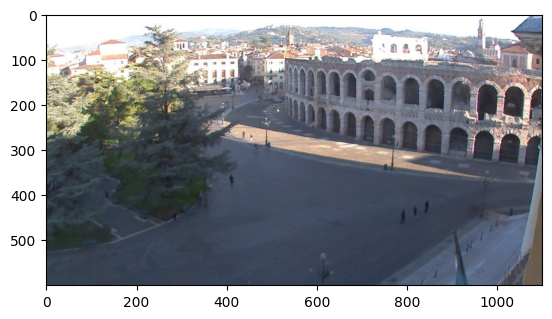

In [16]:
	# Check on random image
	rand_img = np.random.randint(0, len(train_std_img_list))

	feature_img = train_std_img_list[rand_img][0]

	avg_img = avg_brightness(feature_img)

	print(f'Image {rand_img}')
	print(f'Avg Brighness: {avg_img:.4f}')
	plt.imshow(feature_img)

## **Langkah 5 - Klasifikasi dengan Metode Threshold**

In [17]:
	def predict_label(img, threshold):
	    # Computer average brightness
	    avg = avg_brightness(img)
	    pred = 0

	    # Predict the label based on user defined threshold
	    if avg > threshold:
	        pred = 1

	    return pred

**Lakukan pengecekan prediksi secara acak pada data training**

Image 4
Actual label: 0
Predicted label: 0


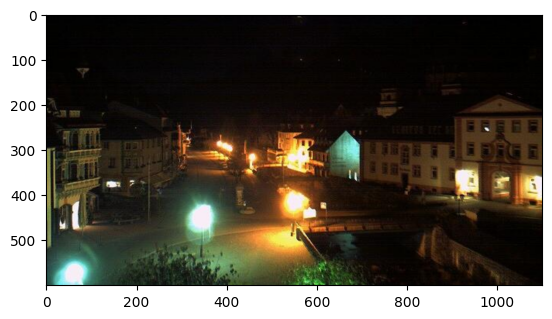

In [18]:
	# Test the classifier on train data
	rand_img = np.random.randint(0, len(train_std_img_list))

	pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

	# Evaluate
	print(f'Image {rand_img}')
	print(f'Actual label: {train_std_img_list[rand_img][1]}')
	print(f'Predicted label: {pred}')
	plt.imshow(train_std_img_list[rand_img][0])

## **Langkah 6 - Evaluasi Manual**

In [19]:
	def evaluate(img_list, threshold):
	    miss_labels = []

	    for file in img_list:
	        # Get the ground truth / correct label
	        img = file[0]
	        label = file[1]

	        # Get prediction
	        pred_label = predict_label(img, threshold)

	        # Compare ground truth and pred
	        if pred_label != label:
	            miss_labels.append((img, pred_label, label))

	    total_img = len(img_list)
	    corr_pred = total_img - len(miss_labels)
	    accuracy = corr_pred / total_img

	    print(f'Accuracy: {accuracy:.4f}')

**Evaluasi pada data training dengan nilai ambang batas 120.**

In [20]:
	# Evaluate on train data
	evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


**Selanjutnya, kita akan melakukan evaluasi pada data testing. Namun sebelumnya, data testing harus diperlakukan sama dengan data training dalam konteks pra progolahan data dan ekstraksi fitur.**

In [21]:
	# Evaluate on test data

	# Load test data
	test_img = load_dataset(test_dir)

	# Preprocess
	test_std_img_list = preprocess(test_img)

	# Predict
	evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


# **Klasifikasi dengan SVM**

## **Langkah 4 Alternatif - Membuat Feature Vectors.**

In [22]:
	# Create function to extract feature for every images and stored in tabular data
	# Stored in Pandas dataframe
	def extract_avg_bright_feature(img_list):
	    avg_list = []
	    labels = []

	    for img in img_list:
	        img_avg = avg_brightness(img[0]) # Get the avg brightness from image
	        img_label = img[1] # Get the image label

	        avg_list.append(img_avg)
	        labels.append(img_label)

	    # Stack data in columcular way
	    data = np.column_stack((avg_list, labels))
	    # Create a Pandas dataframe
	    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

	    return df

**Cek hasilnya pada data training,**

In [23]:
	# Extract feature on train data
	train_avg_img = extract_avg_bright_feature(train_std_img_list)
	print(f'Shape: {train_avg_img.shape}')
	train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,26.946276,0.0
1,114.386045,0.0
2,36.167309,0.0
3,89.905798,0.0
4,48.713038,0.0


**Lakukan langkah yang serupa pada data testing**

In [24]:
	# Do the same thing on test data
	test_avg_img = extract_avg_bright_feature(test_std_img_list)
	print(f'Shape: {test_avg_img.shape}')
	test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,37.642245,0.0
1,38.777894,0.0
2,26.358703,0.0
3,41.211485,0.0
4,53.467780,0.0


## **Langkah 5 - Buat Model SVM**

In [25]:
	# import requied library
	from sklearn.svm import SVC

	# Split data and label
	X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
	y_train = train_avg_img.iloc[:,1]
	X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
	y_test = test_avg_img.iloc[:,1]

	model = SVC()
	model.fit(X_train, y_train)

SVC()

## **Langkah 6 - Evaluasi**

In [26]:
	from sklearn.metrics import accuracy_score

	# Make a prediction on train data
	y_train_pred = model.predict(X_train)

	# Get the accuracy on train data
	acc_train = accuracy_score(y_train, y_train_pred)

	# Make a prediction on test data
	y_test_pred = model.predict(X_test)

	# Get the accuracy on test data
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print Eval Result
	print(f'Accuracy on train: {acc_train}')
	print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
